<!-- The goal of this homework is to create a regression model for predicting the car fuel efficiency (column 'fuel_efficiency_mpg'). -->

In [ ]:
%mamba install pandas numpy matplotlib seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...


error decoding response body

In [63]:
# Phase 2: Data preparation
# Step 1: Load and inspect the dataset
import pandas as pd
import numpy as np

df = pd.read_csv('Car_fuel_efficiency_2026.csv')

# Step 2: Inspect the dataset

print("\nFirst 5 Rows")
print(df.head())

print("DATASET OVERVIEW")
df.shape

print(f"Columns: {list(df.columns)}")

statistical_summary = df.describe()
print(f"\nStatistical Summary:\n{statistical_summary}")


print("\nData Types & Memory Info")
df.info()

# Step 3: Investigate data quality
missing_count = df.isnull().sum()
print(f"\nMissing_count:\n{missing_count}")

duplicate_count = df.duplicated().sum()
print(f"\nDuplicate Rows:\n{duplicate_count}")

n_unique = df.nunique()
print(f"\nNo_of_unique_cols:\n{n_unique}")




First 5 Rows
   model_year  origin fuel_type         drivetrain  num_doors  \
0        2006  Europe  Gasoline  Front-wheel drive          4   
1        2008  Europe    Diesel  Front-wheel drive          4   
2        1996    Asia  Gasoline  Front-wheel drive          5   
3        1989  Europe  Gasoline  Front-wheel drive          4   
4        1994     USA    Diesel  Front-wheel drive          3   

   engine_displacement  num_cylinders  horsepower  vehicle_weight  \
0                 2180              6       243.0            3870   
1                 2390              6       272.0            4210   
2                 2320              6       267.0            4240   
3                 2130              6       258.0            4490   
4                 2580              7       304.0            4510   

   acceleration  fuel_efficiency_mpg  
0           NaN                 31.9  
1           NaN                 31.3  
2          17.3                 27.5  
3          18.7         

In [64]:
# Step 3: Standardise column names

df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(' ', '_')
)

print("\nSTANDARDISED COLUMN NAMES")

for column in df.columns:
    print(column)


STANDARDISED COLUMN NAMES
model_year
origin
fuel_type
drivetrain
num_doors
engine_displacement
num_cylinders
horsepower
vehicle_weight
acceleration
fuel_efficiency_mpg


In [65]:
# Step 4: Standardise categorical values

categorical_columns = df.select_dtypes(include=['object', 'str']).columns

for column in categorical_columns:
    df[column] = (
        df[column]
        .str.strip()
        .str.lower()
        .str.replace(' ', '_')
    )

print("\nCATEGORICAL VALUE STANDARDISATION")
for column in categorical_columns:
    print(f"\n{column.upper()}")
    print(df[column].value_counts().to_string())


CATEGORICAL VALUE STANDARDISATION

ORIGIN
origin
usa       4202
asia      2994
europe    2804

FUEL_TYPE
fuel_type
gasoline    6913
diesel      2053
hybrid      1034

DRIVETRAIN
drivetrain
front-wheel_drive    5519
rear-wheel_drive     2455
all-wheel_drive      2026


In [66]:
# MISSING VALUE TREATMENT: STATISTICAL REVIEW

columns_with_missing = ['horsepower', 'acceleration']

print("MEAN AND MEDIAN COMPARISON")
for column in columns_with_missing:

    print(f"\nFeature: {column.upper()}")

    print(f"Mean:   {df[column].mean():.2f}")
    print(f"Median: {df[column].median():.2f}")
    print(f"Missing: {df[column].isnull().sum()}")

MEAN AND MEDIAN COMPARISON

Feature: HORSEPOWER
Mean:   254.45
Median: 254.00
Missing: 877

Feature: ACCELERATION
Mean:   18.89
Median: 18.90
Missing: 264


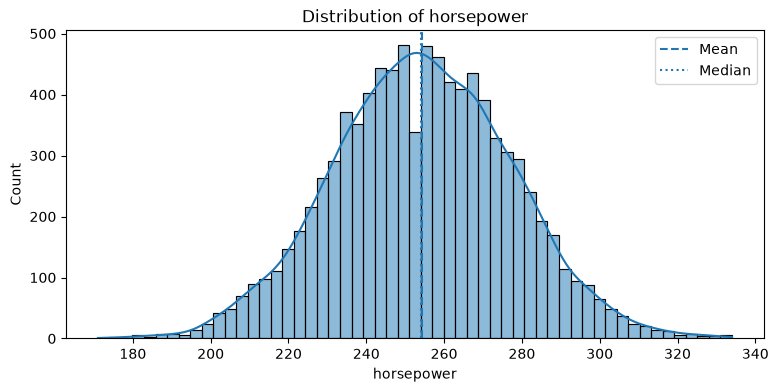

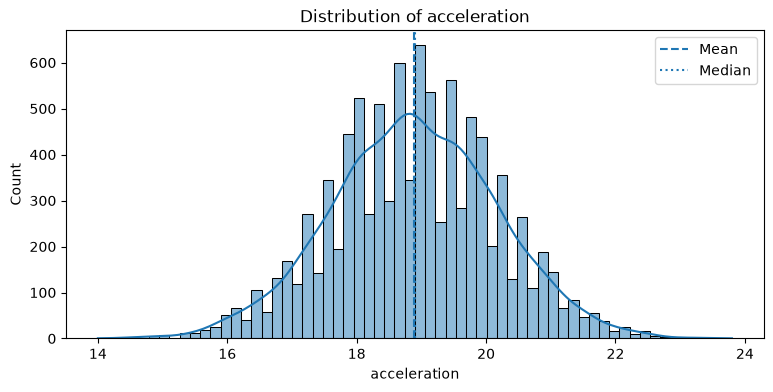

In [67]:
# MISSING VALUE TREATMENT: DISTRIBUTIONS

for column in columns_with_missing:

    plt.figure(figsize=(9, 4))

    sns.histplot(
        data=df,
        x=column,
        kde=True
    )

    plt.axvline(
        df[column].mean(),
        linestyle='--',
        label='Mean'
    )

    plt.axvline(
        df[column].median(),
        linestyle=':',
        label='Median'
    )

    plt.title(f'Distribution of {column}')
    plt.legend()

    plt.show()

In [68]:
# MISSING VALUE TREATMENT: MEDIAN IMPUTATION

columns_with_missing = ['horsepower', 'acceleration']

for column in columns_with_missing:

    median_value = df[column].median()

    df[column] = df[column].fillna(median_value)

    print(f"{column}: Missing values replaced with {median_value:.2f}")

horsepower: Missing values replaced with 254.00
acceleration: Missing values replaced with 18.90


In [69]:
# VERIFY MISSING VALUE TREATMENT

print("MISSING VALUES AFTER IMPUTATION")

print(df.isnull().sum().to_string())

print(f"\nTotal missing values: {df.isnull().sum().sum()}")

MISSING VALUES AFTER IMPUTATION
model_year             0
origin                 0
fuel_type              0
drivetrain             0
num_doors              0
engine_displacement    0
num_cylinders          0
horsepower             0
vehicle_weight         0
acceleration           0
fuel_efficiency_mpg    0

Total missing values: 0


In [70]:
# MISSING VALUE INVESTIGATION

print("MISSING VALUES: HORSEPOWER")

missing_horsepower = df[df['horsepower'].isnull()]

print(f"Total missing records: {len(missing_horsepower)}")
print("\nSample records:")
print(missing_horsepower.head(10).to_string(index=False))

print("MISSING VALUES: ACCELERATION")

missing_acceleration = df[df['acceleration'].isnull()]

print(f"Total missing records: {len(missing_acceleration)}")
print("\nSample records:")
print(missing_acceleration.head(10).to_string(index=False))

print("FUEL EFFICIENCY COMPARISON")

horsepower_comparison = df.groupby(
    df['horsepower'].isnull()
)['fuel_efficiency_mpg'].mean()

print("\nAverage fuel efficiency by horsepower availability:")
print(horsepower_comparison.to_string())


acceleration_comparison = df.groupby(
    df['acceleration'].isnull()
)['fuel_efficiency_mpg'].mean()

print("\nAverage fuel efficiency by acceleration availability:")
print(acceleration_comparison.to_string())

MISSING VALUES: HORSEPOWER
Total missing records: 0

Sample records:
Empty DataFrame
Columns: [model_year, origin, fuel_type, drivetrain, num_doors, engine_displacement, num_cylinders, horsepower, vehicle_weight, acceleration, fuel_efficiency_mpg]
Index: []
MISSING VALUES: ACCELERATION
Total missing records: 0

Sample records:
Empty DataFrame
Columns: [model_year, origin, fuel_type, drivetrain, num_doors, engine_displacement, num_cylinders, horsepower, vehicle_weight, acceleration, fuel_efficiency_mpg]
Index: []
FUEL EFFICIENCY COMPARISON

Average fuel efficiency by horsepower availability:
horsepower
False    29.9977

Average fuel efficiency by acceleration availability:
acceleration
False    29.9977


In [71]:
# Phase 3: Exploratory Data Analysis (EDA)

numerical_columns = df.select_dtypes(include=['int64', 'float64']).columns

categorical_columns = df.select_dtypes(include=['object', 'str']).columns

print("NUMERICAL FEATURES")

for column in numerical_columns:
    print(column)

print("!!CATEGORICAL FEATURES!!")
for column in categorical_columns:
    print(column)

NUMERICAL FEATURES
model_year
num_doors
engine_displacement
num_cylinders
horsepower
vehicle_weight
acceleration
fuel_efficiency_mpg
!!CATEGORICAL FEATURES!!
origin
fuel_type
drivetrain


FUEL EFFICIENCY STATISTICAL SUMMARY
count    10000.000000
mean        29.997700
std          2.930245
min         19.800000
25%         28.000000
50%         30.000000
75%         31.900000
max         41.200000


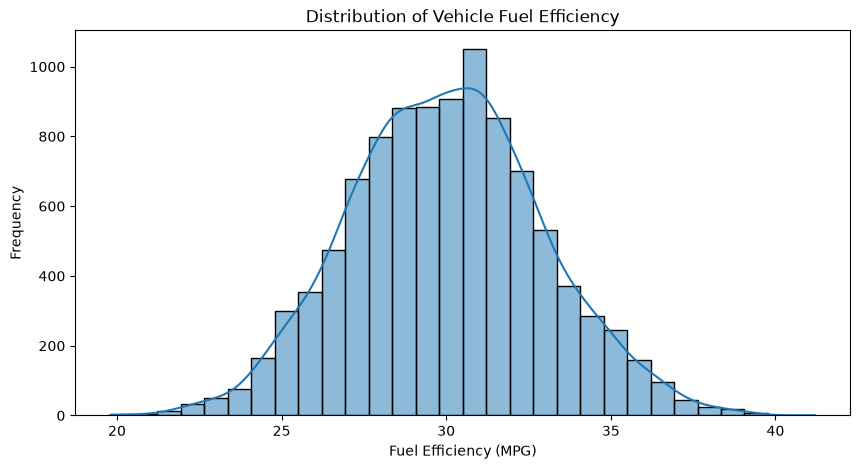

In [72]:
# Step 2: Analyse the target variable

target_column = 'fuel_efficiency_mpg'

print("FUEL EFFICIENCY STATISTICAL SUMMARY")

print(df[target_column].describe().to_string())

# Next, visualise its distribution.

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    df[target_column],
    bins=30,
    kde=True
)

plt.title('Distribution of Vehicle Fuel Efficiency')
plt.xlabel('Fuel Efficiency (MPG)')
plt.ylabel('Frequency')

plt.show()

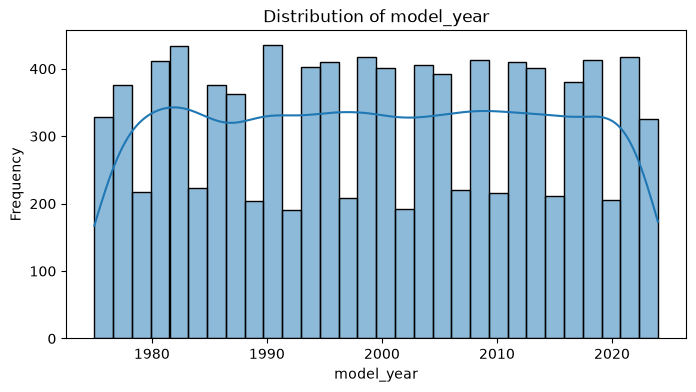

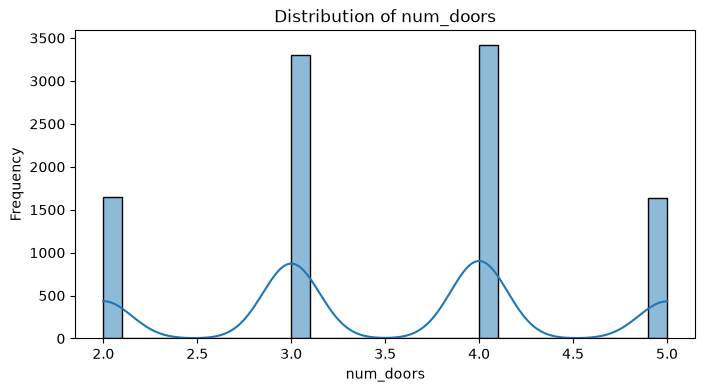

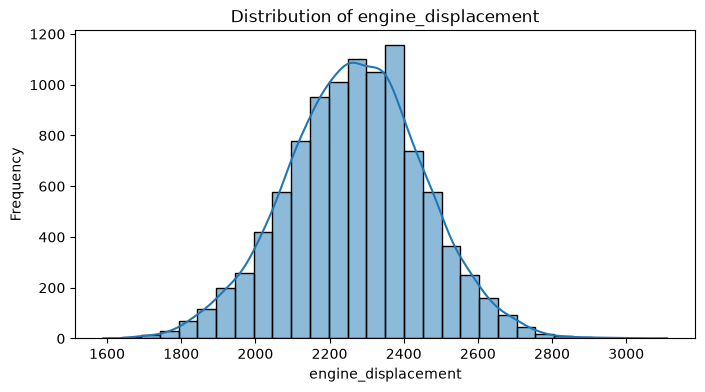

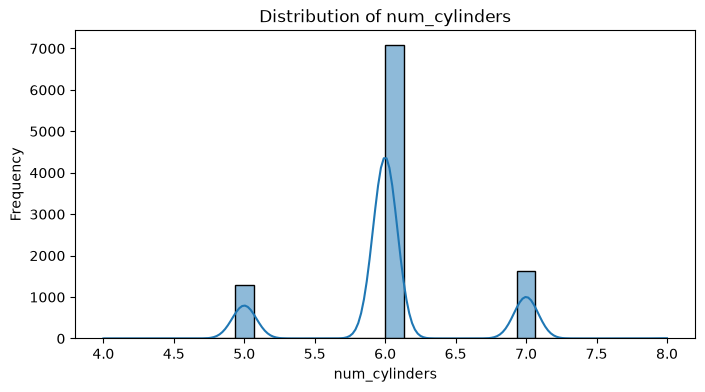

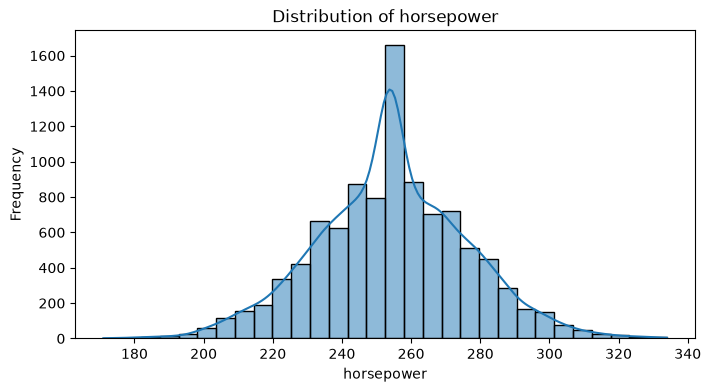

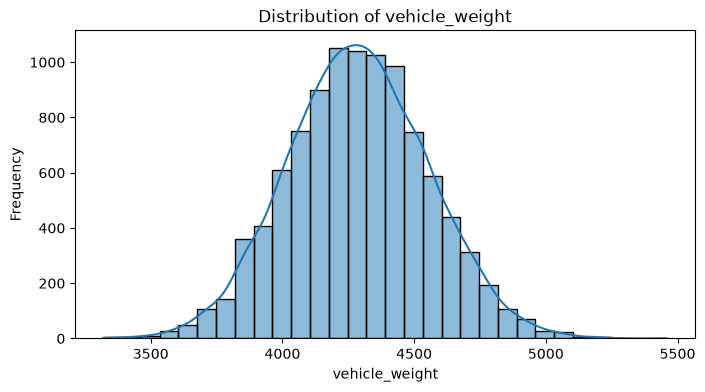

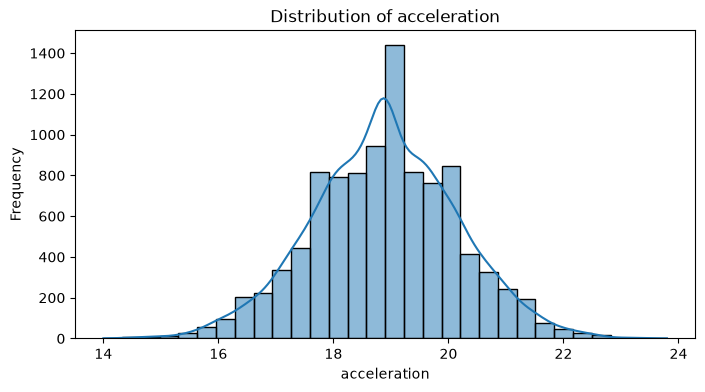

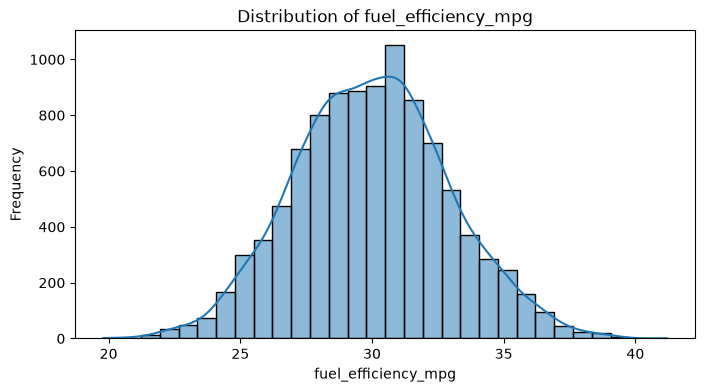

In [73]:
# Step 3: Analyse numerical feature distributions
# We also need to understand the distributions of our independent numerical variables.

for column in numerical_columns:

    plt.figure(figsize=(8, 4))

    sns.histplot(
        df[column],
        bins=30,
        kde=True
    )

    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')

    plt.show()

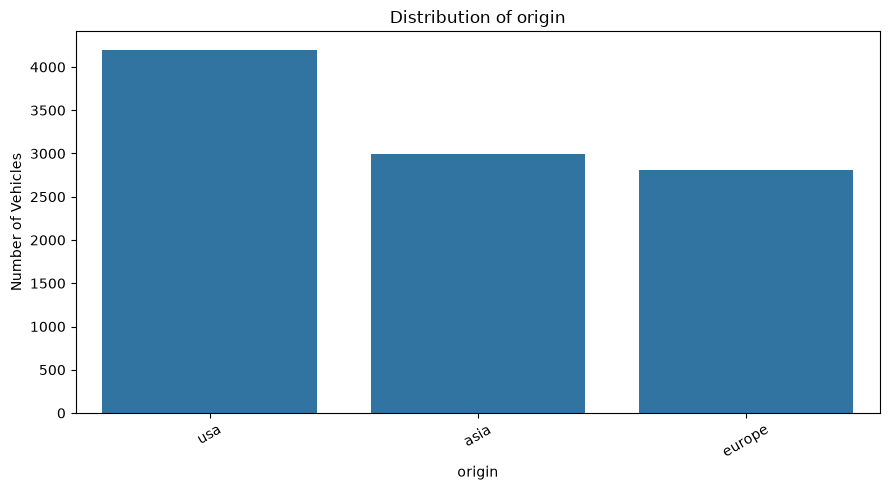

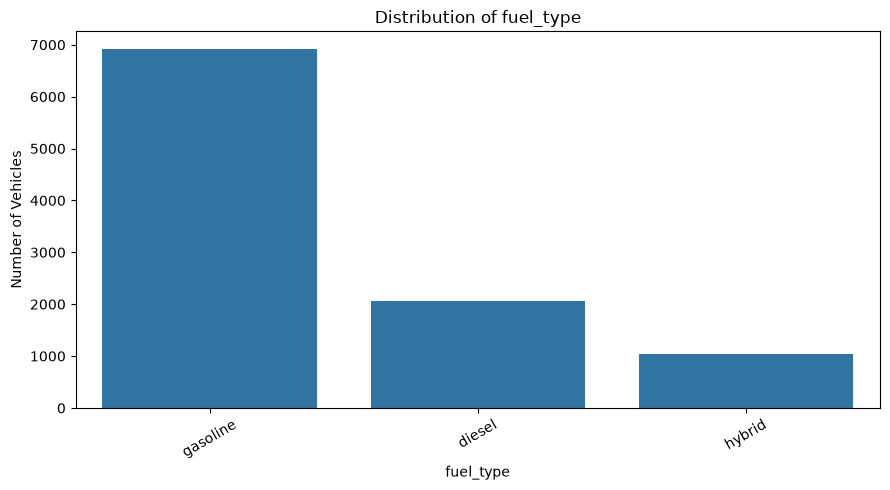

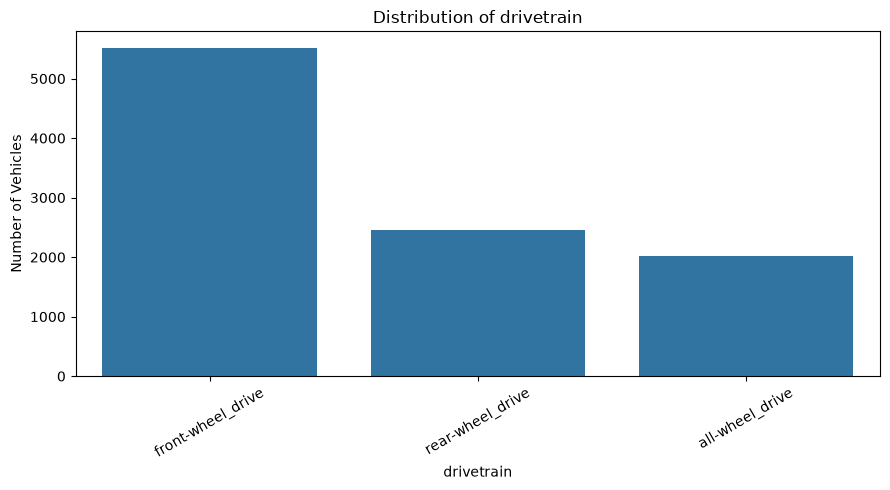

In [74]:
# Step 4: Analyse categorical features

for column in categorical_columns:

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x=column,
        order=df[column].value_counts().index
    )

    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Number of Vehicles')

    plt.xticks(rotation=30)

    plt.tight_layout()
    plt.show()

CORRELATION WITH FUEL EFFICIENCY
fuel_efficiency_mpg    1.000000
model_year             0.500183
num_doors             -0.021136
acceleration          -0.147645
num_cylinders         -0.247331
horsepower            -0.302311
engine_displacement   -0.348174
vehicle_weight        -0.427438


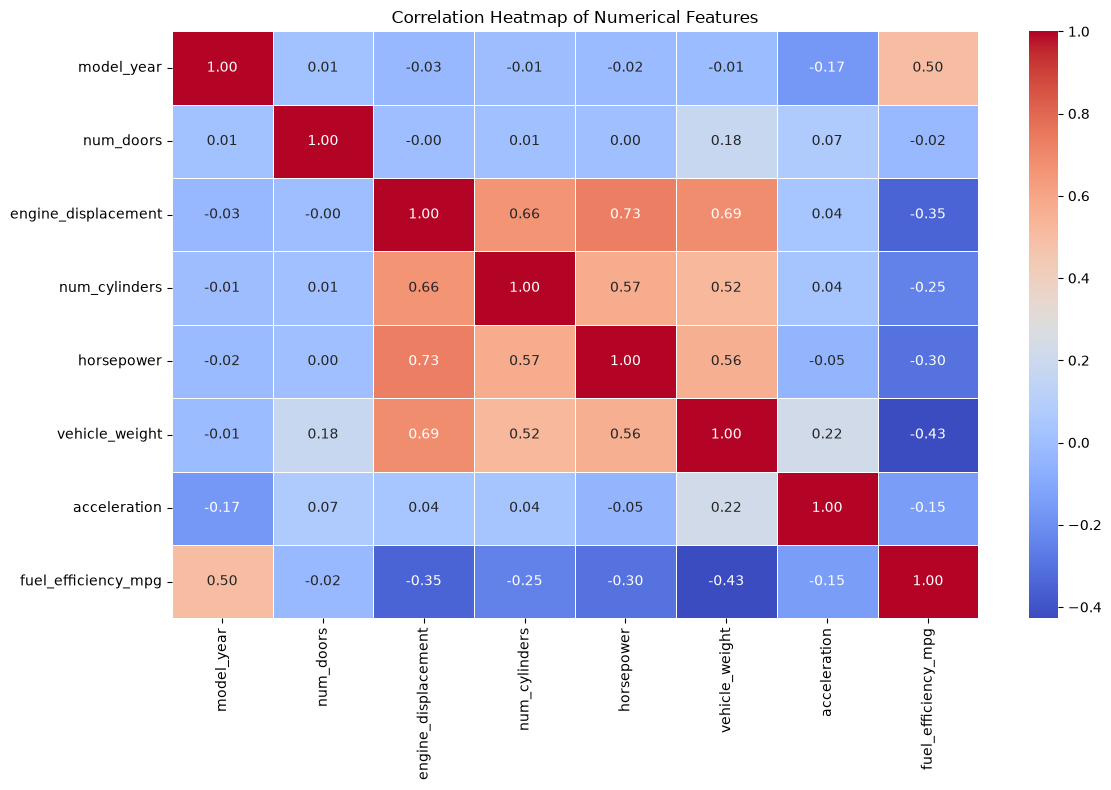

In [75]:
# Step 5: Correlation analysis
# We want to investigate how numerical variables relate to one another and to our target variable.

correlation_matrix = df[numerical_columns].corr()

print("CORRELATION WITH FUEL EFFICIENCY")


target_correlation = correlation_matrix[target_column].sort_values(
    ascending=False
)

print(target_correlation.to_string())

# Now visualise the correlation matrix:

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Features')

plt.tight_layout()
plt.show()

In [76]:
# QUESTION 2: MEDIAN HORSEPOWER

horsepower_median = df['horsepower'].median()

print("QUESTION 2: MEDIAN HORSEPOWER")

print(f"Median horsepower: {horsepower_median}")

QUESTION 2: MEDIAN HORSEPOWER
Median horsepower: 254.0


In [77]:
!mamba install scikit-learn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn, scikit-learn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 8.873 seconds
  Name                Version     Build                Channel
----------------------------------------------------------------------------
+ ca-certificates     2026.10.23  hbd8a1cb_0           conda-forge
+ certifi             2026.10.23  pyhd8ed1ab_3         conda-forge
+ charset-normalizer  3.5.1       pyhd8ed1ab_0         conda-forge
+ idna                3.20        pyh5ded981_0         conda-forge
+ joblib              1.6.0       py313h57e9779_0      emscripten-forge-4x
+ narwhals            2.28.0      pyh5ded981_0         conda-forge
+ requests            2.34.2      pyhcf101f3_0         conda-forge
+ scikit-learn        1.9.1       np23py313hde19dca_0  emscripten-forge-4x
+ setuptools          84.2.1      pyhe730653_0         conda-forge
+ threadpoolctl 

In [78]:
# validation framework.
# RELOAD THE ORIGINAL DATASET

df = pd.read_csv('Car_fuel_efficiency_2026.csv')

print("Original dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum().to_string())

# SPLIT DATA INTO TRAINING, VALIDATION AND TEST

from sklearn.model_selection import train_test_split

# First split: 60% training, 40% temporary
df_train, df_temp = train_test_split(
    df,
    test_size=0.4,
    random_state=42
)

# Second split: 20% validation, 20% test
df_val, df_test = train_test_split(
    df_temp,
    test_size=0.5,
    random_state=42
)

# Display dataset sizes
print("DATASET SPLIT SUMMARY")
print(f"Training set:   {len(df_train)}")
print(f"Validation set: {len(df_val)}")
print(f"Test set:       {len(df_test)}")

print(f"Total records:  {len(df_train) + len(df_val) + len(df_test)}")

Original dataset shape: (10000, 11)

Missing values:
model_year               0
origin                   0
fuel_type                0
drivetrain               0
num_doors                0
engine_displacement      0
num_cylinders            0
horsepower             877
vehicle_weight           0
acceleration           264
fuel_efficiency_mpg      0
DATASET SPLIT SUMMARY
Training set:   6000
Validation set: 2000
Test set:       2000
Total records:  10000


In [79]:
# Separate features from the target

target = 'fuel_efficiency_mpg'

# Training data
X_train = df_train.drop(columns=[target])
y_train = df_train[target]

# Validation data
X_val = df_val.drop(columns=[target])
y_val = df_val[target]

# Test data
X_test = df_test.drop(columns=[target])
y_test = df_test[target]



print("FEATURE AND TARGET SHAPES")

print(f"X_train: {X_train.shape}")
print(f"y_train: {y_train.shape}")

print(f"X_val:   {X_val.shape}")
print(f"y_val:   {y_val.shape}")

print(f"X_test:  {X_test.shape}")
print(f"y_test:  {y_test.shape}")

FEATURE AND TARGET SHAPES
X_train: (6000, 10)
y_train: (6000,)
X_val:   (2000, 10)
y_val:   (2000,)
X_test:  (2000, 10)
y_test:  (2000,)


In [80]:
# Handle missing values without data leakage

columns_to_impute = ['horsepower', 'acceleration']

# Calculate medians using training data only
train_medians = X_train[columns_to_impute].median()

print("MEDIAN VALUES FROM TRAINING DATA")
print(train_medians.to_string())

# APPLY MEDIAN IMPUTATION

X_train[columns_to_impute] = X_train[columns_to_impute].fillna(train_medians)

X_val[columns_to_impute] = X_val[columns_to_impute].fillna(train_medians)

X_test[columns_to_impute] = X_test[columns_to_impute].fillna(train_medians)


# VERIFY MISSING VALUES

print("\nMISSING VALUES AFTER IMPUTATION")

print("Training:", X_train.isnull().sum().sum())
print("Validation:", X_val.isnull().sum().sum())
print("Test:", X_test.isnull().sum().sum())

MEDIAN VALUES FROM TRAINING DATA
horsepower      254.0
acceleration     18.9

MISSING VALUES AFTER IMPUTATION
Training: 0
Validation: 0
Test: 0


In [81]:
# Feature engineering and categorical encoding
# But before we write any code, let's inspect our actual categorical values.

categorical_columns = X_train.select_dtypes(include=['object', 'str']).columns

print("CATEGORICAL FEATURES")

for column in categorical_columns:
    print(f"\n{column.upper()}")
    print(X_train[column].value_counts().to_string())

CATEGORICAL FEATURES

ORIGIN
origin
USA       2545
Asia      1772
Europe    1683

FUEL_TYPE
fuel_type
Gasoline    4125
Diesel      1241
Hybrid       634

DRIVETRAIN
drivetrain
Front-wheel drive    3266
Rear-wheel drive     1497
All-wheel drive      1237


In [86]:
# Let's implement One-Hot Encoding

# Encode training data
X_train_encoded = pd.get_dummies(
    X_train,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

X_val_encoded = pd.get_dummies(
    X_val,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

# Encode test data
X_test_encoded = pd.get_dummies(
    X_test,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)


# ALIGN VALIDATION AND TEST FEATURES

X_val_encoded = X_val_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

X_test_encoded = X_test_encoded.reindex(
    columns=X_train_encoded.columns,
    fill_value=0
)

# VERIFY ENCODING
print("FEATURE SHAPES AFTER ENCODING")

print(f"Training:   {X_train_encoded.shape}")
print(f"Validation: {X_val_encoded.shape}")
print(f"Test:       {X_test_encoded.shape}")

print("\nENCODED FEATURE NAMES")
print(X_train_encoded.columns.to_list())

FEATURE SHAPES AFTER ENCODING
Training:   (6000, 13)
Validation: (2000, 13)
Test:       (2000, 13)

ENCODED FEATURE NAMES
['model_year', 'num_doors', 'engine_displacement', 'num_cylinders', 'horsepower', 'vehicle_weight', 'acceleration', 'origin_Europe', 'origin_USA', 'fuel_type_Gasoline', 'fuel_type_Hybrid', 'drivetrain_Front-wheel drive', 'drivetrain_Rear-wheel drive']


In [87]:
# Establish our baseline model

# Step 1: Prepare the data for NumPy
X_train_np = X_train_encoded.to_numpy()
X_val_np = X_val_encoded.to_numpy()

y_train_np = y_train.to_numpy()
y_val_np = y_val.to_numpy()

# Verify dimensions
print("NUMPY ARRAY SHAPES")
print("X_train:", X_train_np.shape)
print("y_train:", y_train_np.shape)
print("X_val:  ", X_val_np.shape)
print("y_val:  ", y_val_np.shape)

# Define the function
def train_linear_regression(X, y):
    # Add the bias column
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    # Calculate weights using the normal equation
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)

    w_full = XTX_inv.dot(X.T).dot(y)

    # Separate bias and feature weights
    w0 = w_full[0]
    w = w_full[1:]

    return w0, w
    
# Step 2: Train the Linear Regression model
w0, w = train_linear_regression(X_train_np, y_train_np)

print("MODEL PARAMETERS")
print(f"Bias (w0): {w0}")
print(f"Number of weights: {len(w)}")

# Step 3: Generate validation predictions
y_pred = w0 + X_val_np.dot(w)

print("VALIDATION PREDICTIONS")
print("First 10 predictions:")
print(y_pred[:10])

NUMPY ARRAY SHAPES
X_train: (6000, 13)
y_train: (6000,)
X_val:   (2000, 13)
y_val:   (2000,)
MODEL PARAMETERS
Bias (w0): -158.31333113264736
Number of weights: 13
VALIDATION PREDICTIONS
First 10 predictions:
[30.13836062 31.06603442 28.5507351  30.55001874 28.86238625 29.00233567
 32.58605504 28.460443   26.04454802 25.26131877]


In [89]:
#Evaluate the model using RMSE

# Step 1: Calculate RMSE
# Calculate prediction errors
errors = y_val_np - y_pred

# Calculate squared errors
squared_errors = errors ** 2

# Calculate Mean Squared Error
mse = squared_errors.mean()

# Calculate Root Mean Squared Error
rmse = np.sqrt(mse)

print("VALIDATION MODEL PERFORMANCE")
print(f"Mean Squared Error: {mse:.4f}")
print(f"Root Mean Squared Error: {rmse:.4f}")

VALIDATION MODEL PERFORMANCE
Mean Squared Error: 2.7466
Root Mean Squared Error: 1.6573


In [90]:
# Establish a baseline for comparison

# Calculate the average fuel efficiency from training data
y_mean = y_train_np.mean()

# Predict the same average for every validation observation
y_baseline_pred = np.full(
    shape=len(y_val_np),
    fill_value=y_mean
)

# Calculate baseline RMSE
baseline_errors = y_val_np - y_baseline_pred
baseline_mse = (baseline_errors ** 2).mean()
baseline_rmse = np.sqrt(baseline_mse)

# Display results
print("SIMPLE BASELINE MODEL")
print(f"Training Mean: {y_mean:.4f} MPG")
print(f"Baseline RMSE: {baseline_rmse:.4f} MPG")

SIMPLE BASELINE MODEL
Training Mean: 30.0178 MPG
Baseline RMSE: 2.9247 MPG


In [91]:
# Examine the model coefficients
# Before introducing regularization or trying another model, let's understand what your trained model learned.

feature_weights = pd.DataFrame({
    'Feature': X_train_encoded.columns,
    'Coefficient': w
})

# Sort features by absolute coefficient magnitude
feature_weights['Absolute_Coefficient'] = (
    feature_weights['Coefficient'].abs()
)

feature_weights = feature_weights.sort_values(
    by='Absolute_Coefficient',
    ascending=False
)

print("LINEAR REGRESSION MODEL COEFFICIENTS")

print(feature_weights.to_string(index=False))

LINEAR REGRESSION MODEL COEFFICIENTS
                     Feature  Coefficient  Absolute_Coefficient
            fuel_type_Hybrid     2.055985              2.055985
          fuel_type_Gasoline    -1.916956              1.916956
drivetrain_Front-wheel drive     1.307287              1.307287
                  origin_USA    -1.253438              1.253438
 drivetrain_Rear-wheel drive     0.451050              0.451050
                  model_year     0.102202              0.102202
               origin_Europe    -0.061879              0.061879
               num_cylinders    -0.037003              0.037003
                   num_doors    -0.016540              0.016540
                acceleration     0.015424              0.015424
                  horsepower    -0.008852              0.008852
         engine_displacement    -0.002112              0.002112
              vehicle_weight    -0.001906              0.001906


In [92]:
# Inspect the model's predictions

comparison = pd.DataFrame({
    'Actual_MPG': y_val_np,
    'Predicted_MPG': y_pred
})

# Calculate prediction errors
comparison['Error'] = (
    comparison['Actual_MPG'] - comparison['Predicted_MPG']
)

# Display the first 15 predictions
print("ACTUAL VS PREDICTED FUEL EFFICIENCY")
print(comparison.head(15).round(2).to_string(index=False))

ACTUAL VS PREDICTED FUEL EFFICIENCY
 Actual_MPG  Predicted_MPG  Error
       30.1          30.14  -0.04
       29.4          31.07  -1.67
       26.5          28.55  -2.05
       29.1          30.55  -1.45
       27.0          28.86  -1.86
       27.2          29.00  -1.80
       30.4          32.59  -2.19
       30.2          28.46   1.74
       29.0          26.04   2.96
       27.6          25.26   2.34
       34.7          32.55   2.15
       32.3          29.65   2.65
       29.5          31.23  -1.73
       34.0          33.23   0.77
       24.3          26.29  -1.99


In [93]:
# Investigate prediction errors across all validation records

# Calculate absolute errors
comparison['Absolute_Error'] = comparison['Error'].abs()

# Calculate error statistics
mean_error = comparison['Error'].mean()
mean_absolute_error = comparison['Absolute_Error'].mean()
maximum_error = comparison['Absolute_Error'].max()

# Display results
print("VALIDATION ERROR ANALYSIS")

print(f"Mean Error: {mean_error:.4f} MPG")
print(f"Mean Absolute Error: {mean_absolute_error:.4f} MPG")
print(f"Maximum Absolute Error: {maximum_error:.4f} MPG")

# Display the 10 largest prediction errors
print("\n10 LARGEST PREDICTION ERRORS")

largest_errors = comparison.nlargest(
    10, 'Absolute_Error'
)

print(largest_errors.round(2).to_string(index=False))

VALIDATION ERROR ANALYSIS
Mean Error: -0.0167 MPG
Mean Absolute Error: 1.3265 MPG
Maximum Absolute Error: 5.2790 MPG

10 LARGEST PREDICTION ERRORS
 Actual_MPG  Predicted_MPG  Error  Absolute_Error
       37.6          32.32   5.28            5.28
       26.0          31.07  -5.07            5.07
       26.8          31.79  -4.99            4.99
       34.1          29.21   4.89            4.89
       31.2          26.36   4.84            4.84
       23.3          28.13  -4.83            4.83
       32.5          27.71   4.79            4.79
       27.2          31.94  -4.74            4.74
       36.1          31.42   4.68            4.68
       29.0          33.57  -4.57            4.57


In [94]:
# Introduce Regularization (Ridge Regression)

# Step 1: Import Ridge Regression
from sklearn.linear_model import Ridge

# Step 2: Train and evaluate Ridge Regression with different alpha values
# Alpha values to experiment with
alphas = [0, 0.001, 0.01, 0.1, 1, 10, 100]

# Store model performance results
ridge_results = []

# Train and evaluate a model for each alpha
for alpha in alphas:

    # Initialize Ridge Regression
    ridge_model = Ridge(alpha=alpha)

    # Train using training data
    ridge_model.fit(X_train_np, y_train_np)

    # Generate validation predictions
    ridge_predictions = ridge_model.predict(X_val_np)

    # Calculate validation RMSE
    ridge_errors = y_val_np - ridge_predictions
    ridge_mse = np.mean(ridge_errors ** 2)
    ridge_rmse = np.sqrt(ridge_mse)

    # Store results
    ridge_results.append({
        'Alpha': alpha,
        'RMSE': ridge_rmse
    })

# Convert results into a DataFrame
ridge_results_df = pd.DataFrame(ridge_results)

# Display results
print("RIDGE REGRESSION PERFORMANCE")
print(ridge_results_df.to_string(index=False))

RIDGE REGRESSION PERFORMANCE
  Alpha     RMSE
  0.000 1.657284
  0.001 1.657284
  0.010 1.657283
  0.100 1.657280
  1.000 1.657246
 10.000 1.656981
100.000 1.659446
